# II. create components

## Targets:
Objects:
- Bus
- Source
- Sink

## Example:
Let's model the electrical components of a house with a PV! If u want, draw a model to visualize the components and their connections. After you can compare with the graph model of oemof.


## 1. Bus

In [1]:
import oemof.solph as solph

# Create electricity bus
bus_electricity = solph.Bus(
    label="electricity"
)

... this one connects the components with the same carrier (defined by label).

## 2. Source
 ### a) a renewable source!
There are various ways to initialize components. Depending on the model and the reason for the optimization, they may be more or less suitable. Always have in mind in oemof capacity has different meanings and weight. Sometimes it describes the power of a component in a flow - sometimes the capacity of a storage.

Let us assume that, in this example, a fixed PV system with a peak output of 10 kW has been installed and the percentage performance is known:

In [3]:
# PV generation profile (normalized)
pv_profile = [ # -
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.08403, 0.24741, 0.308595, 0.39654,
    0.414285, 0.36735, 0.273915, 0.156585, 0.00423, 0.0,
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0
]

pv_capacity = 10000  # Watt

# Create PV source
pv = solph.components.Source(
    label="pv",
    outputs={
        bus_electricity: solph.Flow(
            nominal_capacity=pv_capacity,
            maximum=pv_profile
        )
    }
)

In most cases, time series for PV systems already take energy into account, i.e. the available energy per time step (e.g. Wh/h). Consequently, defining capacity would not be meaningful, as the time series is always interpreted relative to the rated power:

In [4]:
# PV generation profile (absolute)
pv_profile = [ # Wh/h
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 840.3, 2474.1, 3085.95, 3965.4,
    4142.85, 3673.5, 2739.15, 1565.85, 42.3, 0.0,
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0
]

pv_capacity = 1 # -

# Create PV source
pv = solph.components.Source(
    label="pv",
    outputs={
        bus_electricity: solph.Flow(
            nominal_capacity=pv_capacity,
            maximum=pv_profile
        )
    }
)

Whatever the case, the inputs/outputs parameters are always initialized with a dictionary in which the key describes the connected component or bus and the value represents the flow, which describes the configuration of the connection.

Provided that connections are unrestricted, flows can also be initialised without parameters.
On the other hand, they provide a number of parameters for specifying the connection:
https://oemof-solph.readthedocs.io/en/v0.6.4/reference/oemof.solph.flow.html

### b) add a grid
Imagine an electricity grid connection with no limit but with energy consumption costs e.g. 0.30 €/kWh

Task:
```python
grid = solph.components.Source(
    label="grid",
    outputs={
        # TODO: Connect grid to electricity bus

        # TODO: Define flow costs

    }
)
```
Code:

In [5]:
# grid
grid = solph.components.Source(
    label="grid",
    outputs={
        bus_electricity: solph.Flow(
            variable_costs=0.30/1000
        )
    }
)

<details>
<summary><b> Solution</b></summary>

```python
grid = solph.Source(
    label="grid",
    outputs={
        bus_electricity: solph.Flow(
            variable_costs=0.30/1000
        )
    }
)
```

## 3. Sink
### a) Handling the overlaod

As the model is ultimately converted into a system of equations, the system of equations should be solvable. Bear in mind the parameters ‘maximum’ and ‘fix’.
In the example, PV electricity generation is set against household demand. There are not only periods when demand exceeds generation, but also periods when electricity generation exceeds demand.  To account for this, you can create an ‘excess’:

In [6]:
excess = solph.components.Sink(
    label="excess",
    inputs={
        bus_electricity: solph.Flow()
    }
)

### b) add the electricity demand of the household

Add a sink as an electricity demand of an household:
electricity_demand_profile = [
    0.3, 0.25, 0.2, 0.2, 0.25, 0.4,
    0.6, 0.7, 0.5, 0.4, 0.35, 0.35,
    0.4, 0.4, 0.4, 0.45, 0.6, 0.8,
    1.0, 0.9, 0.8, 0.7, 0.5, 0.4
]

Choose a demand_capacity yourself

Task:

```python
demand_electricity = solph.components.Sink(
    # TODO Create electricity demand
)
```
Code:

In [7]:
# demand electricity
electricity_demand_profile = [ 0.3, 0.25, 0.2, 0.2, 0.25, 0.4, 0.6, 0.7, 0.5, 0.4, 0.35, 0.35, 0.4, 0.4, 0.4, 0.45, 0.6, 0.8, 1.0, 0.9, 0.8, 0.7, 0.5, 0.4 ]
demand_capacity = 4000
electricity_demand = solph.components.Sink(
    label="electricity_demand",
    inputs={
        bus_electricity: solph.Flow(
            nominal_capacity=demand_capacity,
            fix=electricity_demand_profile
        )
    }
)

<details>
<summary><b>Solution</b></summary>

```python
electricity_demand = solph.Sink(
    label="electricity_demand",
    inputs={
        bus_electricity: solph.Flow(
            nominal_capacity=demand_capacity,
            fix=demand_profile
        )
    }
)
```

## Finally you should have:
|Component(Node)|solph-class|flow-parameters|
|---------------|-----------|----------|
|electricity_bus|Bus||
|pv|Source|nominal_capacity,maximum|
|grid|Source|variable_costs|
|excess|Sink||
|electrcity_demand|Sink|fix|



## Bored? Add a storage:
https://oemof-solph.readthedocs.io/en/v0.6.4/reference/oemof.solph.components.html#module-oemof.solph.components._generic_storage

In [7]:
# Storage

# III. Energy System - put it all together & visualize
## 1. add components

```python
# TODO: Add an energysystem here before adding the components
...

# TODO Add components to energy system
energysystem.add(...)


# Check the components if wanted:
# for node in energysystem.nodes:
#    print(node.label)
```

In [8]:
# TODO: Add an energysystem here before adding the components
energysystem = solph.EnergySystem(
    timeindex=solph.create_time_index(year=2026,interval=1,number=24)
)

# TODO Add components to energy system
energysystem.add(
    bus_electricity,
    pv,
    grid,
    electricity_demand,
    excess
)

# Check the components if wanted:
for node in energysystem.nodes:
    print(node.label)

electricity
pv
grid
electricity_demand
excess


<details>
<summary><b>Solution</b></summary>

```python
# TODO: Add an energysystem here before adding the components
energysystem = solph.EnergySystem(
    timeindex=solph.create_time_index(year=2026,interval=1,number=24)
)
# TODO Add components to energy system
energysystem.add(
    bus_electricity,
    pv,
    grid,
    demand_electricity,
    excess
)

# Check the components if wanted:
for node in energysystem.nodes:
    print(node.label)
```

## 2. use the helper function to visualize
To simplify matters, the graphical output has been hidden in a helper script: helpers/visualization.py

To display the graphs: plot_energy_system

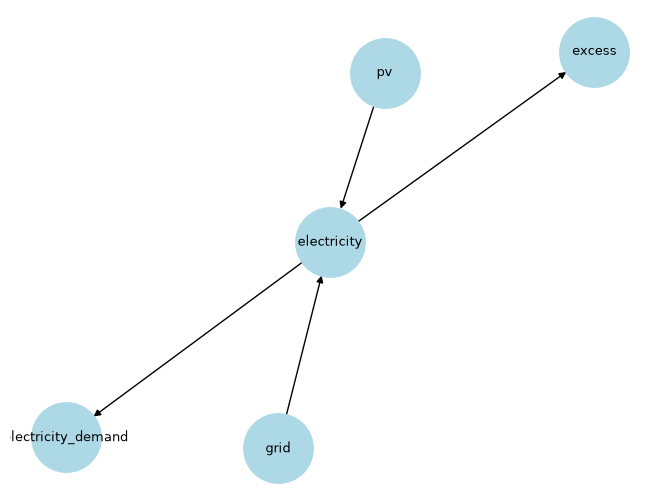

In [9]:
from helpers.visualize import plot_energy_system
plot_energy_system(energysystem)
